# Kepler Exoplanet Candidate Vetting with Binary Logistic Regression
**Course:** Statistical Analysis through Programming  
**Dataset:** NASA Kepler Objects of Interest (KOI) cumulative table (`cumulative.csv`, Kaggle)  
**Tools:** `pandas`, `numpy`, `scipy.stats`, `statsmodels`, `scikit-learn`, `matplotlib`

## 1. Problem Statement

The Kepler space telescope monitored the brightness of ~150,000 stars. When a planet passes in front of its host star (a **transit**), the measured flux dips by a small fraction, the *transit depth*. Depth, duration and period carry physical information:

$$\text{depth} \approx \left(\frac{R_p}{R_\star}\right)^2 \qquad\Longrightarrow\qquad R_p \approx R_\star\sqrt{\text{depth}}$$

A periodic dip is **not** proof of a planet. Many signals are **false positives**, for example:

* **Eclipsing binaries (EBs):** a stellar companion eclipsing its host star, or a background EB blended into the aperture, can mimic a shallow, planet-like dip.
* **Grazing eclipses** of large stars, which give short, V-shaped dips that look like small-planet transits.
* **Instrumental or stellar variability** (starspots, pulsations, systematics).

Each Kepler Object of Interest (KOI) is eventually labelled `CONFIRMED`, `FALSE POSITIVE` or left as `CANDIDATE`. In this notebook we ask a statistical question:

> **Can the physical and orbital measurements of a transit signal alone distinguish confirmed planets from false positives, and which measurements carry the most evidence?**

We use **binary logistic regression** twice: first for *inference* (`statsmodels`: coefficients, odds ratios, confidence intervals), then for *prediction* (`scikit-learn`: accuracy, ROC, threshold choice).

## 2. Environment Setup & Data Cleaning

We import only the permitted libraries, fix a global random seed (`42`), and set a clean, high-resolution `matplotlib` style.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
from IPython.display import display

SEED = 42
np.random.seed(SEED)

# Consistent colours: planets vs. false positives
C_PLANET, C_FP = "#1b9e77", "#d95f02"

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.titlesize": 12, "axes.labelsize": 11, "legend.frameon": False,
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

### 2.1 Load the data and select the two target classes

`koi_disposition` has three values. `CANDIDATE` rows have **no definitive label**, so they are dropped. We keep `CONFIRMED` $\rightarrow 1$ and `FALSE POSITIVE` $\rightarrow 0$.

In [2]:
raw = pd.read_csv("cumulative.csv")
print(f"Raw table: {raw.shape[0]:,} rows x {raw.shape[1]} columns\n")
print("Original koi_disposition counts:")
print(raw["koi_disposition"].value_counts().to_string())

labelled = raw[raw["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
labelled["target"] = labelled["koi_disposition"].map({"CONFIRMED": 1, "FALSE POSITIVE": 0})
print(f"\nAfter dropping CANDIDATE rows: {len(labelled):,} rows")

Raw table: 9,564 rows x 50 columns

Original koi_disposition counts:
koi_disposition
FALSE POSITIVE    5023
CONFIRMED         2293
CANDIDATE         2248

After dropping CANDIDATE rows: 7,316 rows


### 2.2 Leakage prevention: which columns we must *not* use

We restrict the model to **nine physical / orbital measurements**:

`koi_period, koi_duration, koi_depth, koi_prad, koi_teq, koi_insol, koi_model_snr, koi_steff, koi_srad`

and **explicitly exclude `koi_score` and every `koi_fpflag_*` column**. This is **target leakage** prevention:

* **`koi_score`** is the pipeline's own confidence that a KOI is a planet. It is an *output of the vetting process* that also produces the label, so it is almost a re-encoding of the target. Using it would measure how well we copy the pipeline, not whether physical measurements discriminate.
* **`koi_fpflag_nt / _ss / _co / _ec`** (not transit-like, stellar eclipse, centroid offset, ephemeris match) are the **diagnostic tests whose outcomes define a `FALSE POSITIVE`**. A raised flag *is* the reason for the label. Moreover, these flags would not be available at the moment we want to make a prediction for a new signal.

A model with such features would score a spuriously high AUC and the coefficients would carry no physical meaning. The next cell shows how strongly these columns are tied to the label.

In [3]:
fp_cols = [c for c in raw.columns if c.startswith("koi_fpflag_")]
labelled["any_fpflag"] = labelled[fp_cols].sum(axis=1) > 0

leak_check = labelled.groupby("koi_disposition").agg(
    mean_koi_score=("koi_score", "mean"),
    share_with_any_fpflag=("any_fpflag", "mean"),
).round(3)
print("Excluded columns:", ["koi_score"] + fp_cols)
display(leak_check)

Excluded columns: ['koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec']


,mean_koi_score,share_with_any_fpflag
koi_disposition,,
CONFIRMED,0.963,0.024
FALSE POSITIVE,0.015,0.979


The mean `koi_score` and the share of objects with a raised flag differ almost completely between the classes, which is the signature of leakage. These columns are therefore **never passed to any model**.

### 2.3 Predictor subset and missing data

We keep the nine allowed predictors, report missing values per column, and drop incomplete rows with `dropna()`.

In [4]:
PREDICTORS = ["koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_teq",
              "koi_insol", "koi_model_snr", "koi_steff", "koi_srad"]

UNITS = {
    "koi_period": "days", "koi_duration": "hours", "koi_depth": "ppm",
    "koi_prad": "R_earth", "koi_teq": "K", "koi_insol": "Earth flux",
    "koi_model_snr": "unitless", "koi_steff": "K", "koi_srad": "R_sun",
}

subset = labelled[PREDICTORS + ["target", "koi_disposition"]].copy()

missing = subset[PREDICTORS].isna().sum().rename("missing_count").to_frame()
missing["missing_pct"] = (100 * missing["missing_count"] / len(subset)).round(2)
print("Missing values per predictor (before dropna):")
display(missing)

n_before = len(subset)
subset = subset.dropna()
print(f"\nRows before dropna(): {n_before:,}")
print(f"Rows after  dropna(): {len(subset):,}  (removed {n_before - len(subset):,})")

Missing values per predictor (before dropna):


,missing_count,missing_pct
koi_period,0,0.00
koi_duration,0,0.00
koi_depth,300,4.10
koi_prad,300,4.10
koi_teq,300,4.10
koi_insol,259,3.54
koi_model_snr,300,4.10
koi_steff,300,4.10
koi_srad,300,4.10



Rows before dropna(): 7,316
Rows after  dropna(): 7,016  (removed 300)


### 2.4 Skewness before vs. after `log10`

Transit quantities (period, depth, radius, SNR, ...) are strictly positive and span several orders of magnitude, so their raw distributions are strongly right-skewed. Logistic regression is linear in the predictors, so a power-law relationship becomes linear after a log transform. We compare skewness (`scipy.stats.skew`) before and after `log10` and keep `koi_steff` on its linear scale because its skewness is already moderate and temperatures do not span orders of magnitude.

`log10` is only defined for positive values, so we first check that no value is $\le 0$.

In [5]:
LOG_COLS = ["koi_period", "koi_duration", "koi_depth", "koi_prad",
            "koi_teq", "koi_insol", "koi_model_snr", "koi_srad"]

# log10 requires strictly positive values
nonpos = (subset[LOG_COLS] <= 0).any(axis=1)
print(f"Rows with a non-positive value in a log-transformed column: {nonpos.sum()}")
subset = subset.loc[~nonpos].copy()

skew_tbl = pd.DataFrame({
    "skew_raw": subset[PREDICTORS].apply(stats.skew),
    "skew_log10": np.log10(subset[PREDICTORS]).apply(stats.skew),
})
skew_tbl["transformation_applied"] = np.where(skew_tbl.index.isin(LOG_COLS), "log10", "none (linear)")
display(skew_tbl.round(2))

# ---- Analysis data frame -------------------------------------------------
data = subset[["koi_disposition", "target"]].copy()
for c in PREDICTORS:
    data[f"log10_{c}" if c in LOG_COLS else c] = np.log10(subset[c]) if c in LOG_COLS else subset[c]

FEATURES = [f"log10_{c}" if c in LOG_COLS else c for c in PREDICTORS]
data = data.reset_index(drop=True)

counts = data["koi_disposition"].value_counts()
print(f"\nFinal sample size: {len(data):,}")
print("Class distribution:")
for name, n in counts.items():
    print(f"  {name:<15s} {n:>5,d}  ({100 * n / len(data):.1f}%)")

Rows with a non-positive value in a log-transformed column: 1


,skew_raw,skew_log10,transformation_applied
koi_period,2.85,0.43,log10
koi_duration,5.88,0.46,log10
koi_depth,4.56,0.96,log10
koi_prad,45.66,0.94,log10
koi_teq,3.19,-0.09,log10
koi_insol,51.34,-0.09,log10
koi_model_snr,4.64,0.99,log10
koi_steff,0.90,-0.48,none (linear)
koi_srad,20.29,2.46,log10



Final sample size: 7,015
Class distribution:
  FALSE POSITIVE  4,723  (67.3%)
  CONFIRMED       2,292  (32.7%)


Skewness drops sharply for every log-transformed predictor (for `koi_prad` and `koi_insol` from values above 45 to below 1). `koi_srad` improves from about 20 to 2.5 but stays right-skewed because of a tail of giant host stars; we keep it on the log scale because that is still a large improvement. From here on, feature names carry a `log10_` prefix when transformed.

## 3. Descriptive Statistics & Hypothesis Testing

### 3.1 Summary statistics by class

Mean, standard deviation, median and interquartile range (IQR) of each predictor (on the analysis scale, i.e. `log10` for the transformed variables), grouped by disposition.

In [6]:
def iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)

summary = (data.groupby("koi_disposition")[FEATURES]
               .agg(["mean", "std", "median", iqr]).T.unstack(level=1))
summary = summary.reindex(
    index=FEATURES,
    columns=pd.MultiIndex.from_product([["CONFIRMED", "FALSE POSITIVE"], ["mean", "std", "median", "iqr"]]),
)
display(summary.round(3))

CONFIRMED                             FALSE POSITIVE                            
                         mean      std    median      iqr           mean      std    median      iqr
log10_koi_period        1.074    0.537     1.054    0.700          0.955    0.924     0.761    1.440
log10_koi_duration      0.564    0.245     0.553    0.324          0.656    0.363     0.621    0.458
log10_koi_depth         2.680    0.506     2.663    0.609          3.173    1.255     2.739    2.052
log10_koi_prad          0.354    0.264     0.336    0.284          0.924    0.823     0.836    1.439
log10_koi_teq           2.879    0.201     2.893    0.273          2.990    0.343     3.039    0.494
log10_koi_insol         1.889    0.805     1.944    1.093          2.333    1.370     2.532    1.977
log10_koi_model_snr     1.584    0.416     1.500    0.431          1.775    0.855     1.467    1.344
koi_steff            5477.974  677.133  5616.000  758.500       5848.830  862.701  5855.000  827.000
log10_koi_srad         -0.008    0.166    -0.014    0.172          0.097    0.305     0.004    0.263

### 3.2 Two-sample tests: Welch's *t* and Mann-Whitney *U*

For each predictor we test whether confirmed planets and false positives differ.

* **Welch's *t*-test** compares means without assuming equal variances ($H_0$: equal means).
* **Mann-Whitney *U*** is rank-based and does not assume normality ($H_0$: neither group is stochastically larger).

We also report **Cohen's *d*** (standardised mean difference) and the **common-language effect size** $U/(n_1 n_0)$ = P(random planet > random false positive). With $n \approx 7{,}000$ almost any difference is "significant", so effect sizes matter. A Bonferroni threshold $\alpha/9$ is applied for the 9 simultaneous tests.

In [7]:
planets = data[data["target"] == 1]
fps = data[data["target"] == 0]
n1, n0 = len(planets), len(fps)
alpha_bonf = 0.05 / len(FEATURES)

rows = []
for f in FEATURES:
    a, b = planets[f].to_numpy(), fps[f].to_numpy()
    t_stat, p_t = stats.ttest_ind(a, b, equal_var=False)
    u_stat, p_u = stats.mannwhitneyu(a, b, alternative="two-sided")
    pooled_sd = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n0 - 1) * b.var(ddof=1)) / (n1 + n0 - 2))
    rows.append({
        "feature": f,
        "Welch t": t_stat, "Welch p": p_t,
        "Mann-Whitney U": u_stat, "MWU p": p_u,
        "Cohen d": (a.mean() - b.mean()) / pooled_sd,
        "P(planet > FP)": u_stat / (n1 * n0),
        "sig. (Bonferroni)": (p_t < alpha_bonf) and (p_u < alpha_bonf),
    })

tests = pd.DataFrame(rows).set_index("feature")
tests_fmt = tests.copy()
for c in ["Welch p", "MWU p"]:
    tests_fmt[c] = tests_fmt[c].map("{:.2e}".format)
tests_fmt["Welch t"] = tests_fmt["Welch t"].map("{:.2f}".format)
tests_fmt["Mann-Whitney U"] = tests_fmt["Mann-Whitney U"].map("{:,.0f}".format)
tests_fmt["Cohen d"] = tests_fmt["Cohen d"].map("{:+.2f}".format)
tests_fmt["P(planet > FP)"] = tests_fmt["P(planet > FP)"].map("{:.3f}".format)
print(f"n(CONFIRMED) = {n1:,},  n(FALSE POSITIVE) = {n0:,},  Bonferroni alpha = {alpha_bonf:.4f}")
display(tests_fmt)

n(CONFIRMED) = 2,292,  n(FALSE POSITIVE) = 4,723,  Bonferroni alpha = 0.0056


,Welch t,Welch p,Mann-Whitney U,MWU p,Cohen d,P(planet > FP),sig. (Bonferroni)
feature,,,,,,,
log10_koi_period,6.76,1.51e-11,"6,291,162",2.35e-28,+0.14,0.581,True
log10_koi_duration,-12.53,1.35e-35,"4,656,515",2.03e-21,-0.28,0.430,True
log10_koi_depth,-23.37,2.87e-116,"4,732,203",1.21e-17,-0.46,0.437,True
log10_koi_prad,-43.24,0.00e+00,"3,647,954",5.26e-109,-0.82,0.337,True
log10_koi_teq,-17.02,1.13e-63,"4,043,650",2.36e-66,-0.37,0.374,True
log10_koi_insol,-17.02,1.13e-63,"4,043,726",2.39e-66,-0.37,0.374,True
log10_koi_model_snr,-12.59,5.71e-36,"5,508,062",2.30e-01,-0.26,0.509,False
koi_steff,-19.61,6.97e-83,"3,984,386",4.64e-72,-0.46,0.368,True
log10_koi_srad,-18.62,1.65e-75,"4,551,866",2.81e-27,-0.39,0.420,True


**Reading the table.** Univariate tests describe *marginal* differences; they do not control for the other predictors. The signs and sizes of effects here can differ from the multivariable logistic model in Section 5. The two tests agree for eight of the nine predictors. The exception is `log10_koi_model_snr`: Welch's *t* detects a difference in means (false positives have a larger mean and a much heavier upper tail, i.e. a larger SD), but Mann-Whitney finds no shift in ranks (P(planet > FP) ≈ 0.51). The two classes have similar *medians* but different spreads, so SNR is not a good *marginal* separator; it becomes important only after adjusting for the other predictors in Section 5.

## 4. Exploratory Visual Analysis

All figures use `matplotlib` only.

### Plot 1: Class distribution

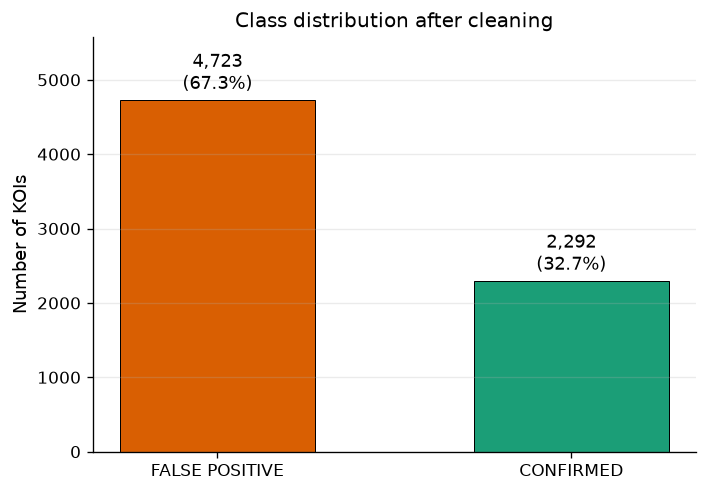

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.2))
order = ["FALSE POSITIVE", "CONFIRMED"]
vals = [counts[k] for k in order]
bars = ax.bar(order, vals, color=[C_FP, C_PLANET], edgecolor="black", linewidth=0.6, width=0.55)
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015 * max(vals),
            f"{v:,}\n({100 * v / len(data):.1f}%)", ha="center", va="bottom", fontsize=11)
ax.set_ylim(0, max(vals) * 1.18)
ax.set_ylabel("Number of KOIs")
ax.set_title("Class distribution after cleaning")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

The classes are imbalanced (about 2 : 1 in favour of false positives). A naive "always predict false positive" classifier would already reach about two-thirds accuracy, so we report precision, recall, F1 and ROC-AUC in Section 6, not accuracy alone. We use **stratified** splitting to preserve the ratio.

### Plot 2: Overlaid normalised histograms

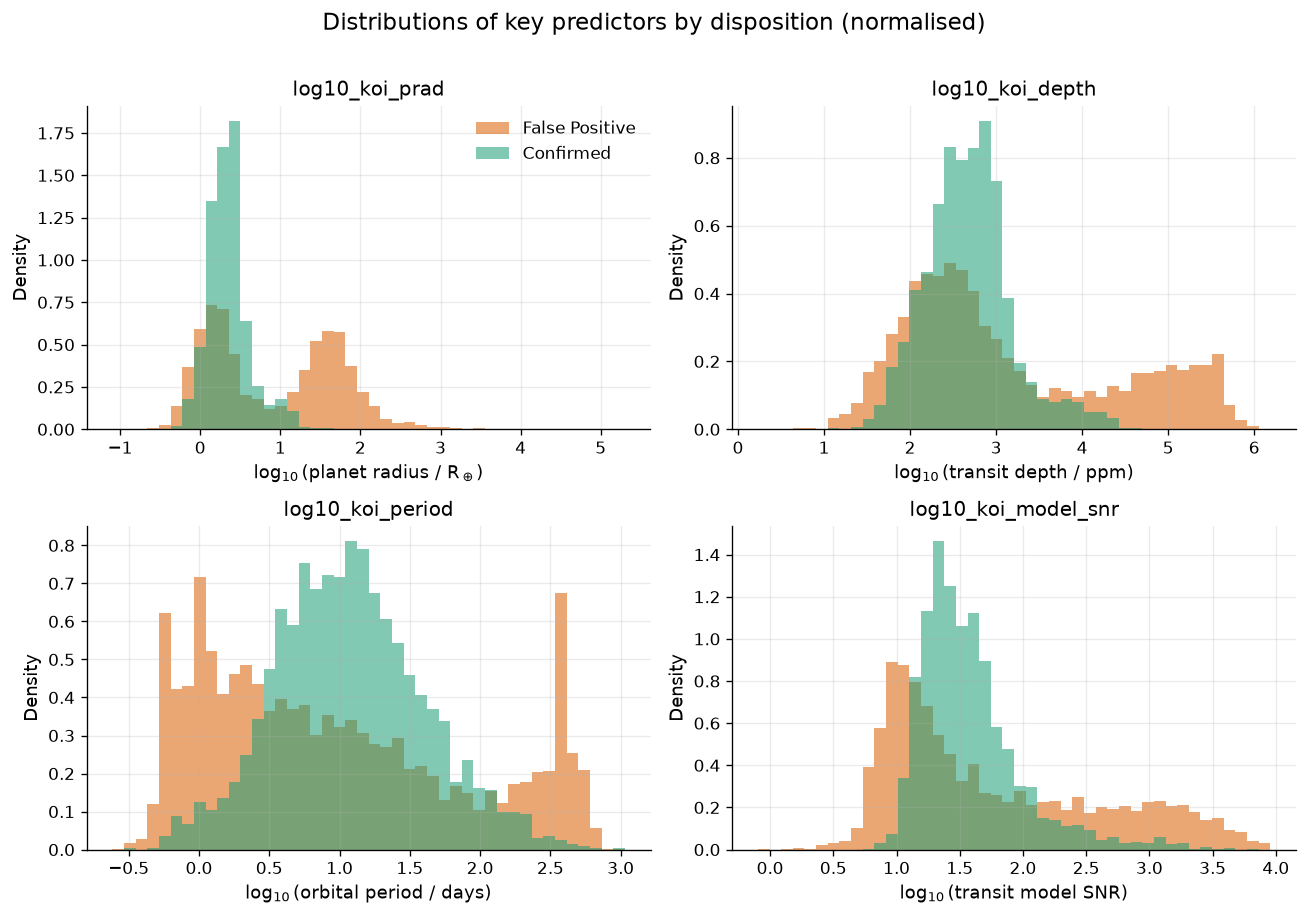

In [9]:
hist_vars = [
    ("log10_koi_prad", r"$\log_{10}$(planet radius / R$_\oplus$)"),
    ("log10_koi_depth", r"$\log_{10}$(transit depth / ppm)"),
    ("log10_koi_period", r"$\log_{10}$(orbital period / days)"),
    ("log10_koi_model_snr", r"$\log_{10}$(transit model SNR)"),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, (col, xlabel) in zip(axes.ravel(), hist_vars):
    bins = np.linspace(data[col].min(), data[col].max(), 45)
    ax.hist(fps[col], bins=bins, density=True, alpha=0.55, color=C_FP, label="False Positive")
    ax.hist(planets[col], bins=bins, density=True, alpha=0.55, color=C_PLANET, label="Confirmed")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Density")
    ax.set_title(col)
axes[0, 0].legend(loc="upper right")
fig.suptitle("Distributions of key predictors by disposition (normalised)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Plot 3: Period vs. radius, with physical regimes

Radii are shown in Earth radii; 1 R$_{Jup}\approx 11.2$ R$_\oplus$. The shaded/dashed regions are approximate, intended as guides.

* **Hot Jupiters:** short period (< 10 d) and large radius (≈ 8-22 R$_\oplus$).
* **Super-Earths / sub-Neptunes:** 1-4 R$_\oplus$, most common at periods of days to months.
* **Stellar-sized signals:** radii above ≈ 2 R$_{Jup}$ (≈ 22 R$_\oplus$) are essentially never planets (planetary radii saturate near 1-2 R$_{Jup}$), so such "planets" are typically eclipsing binaries or grazing stellar eclipses.

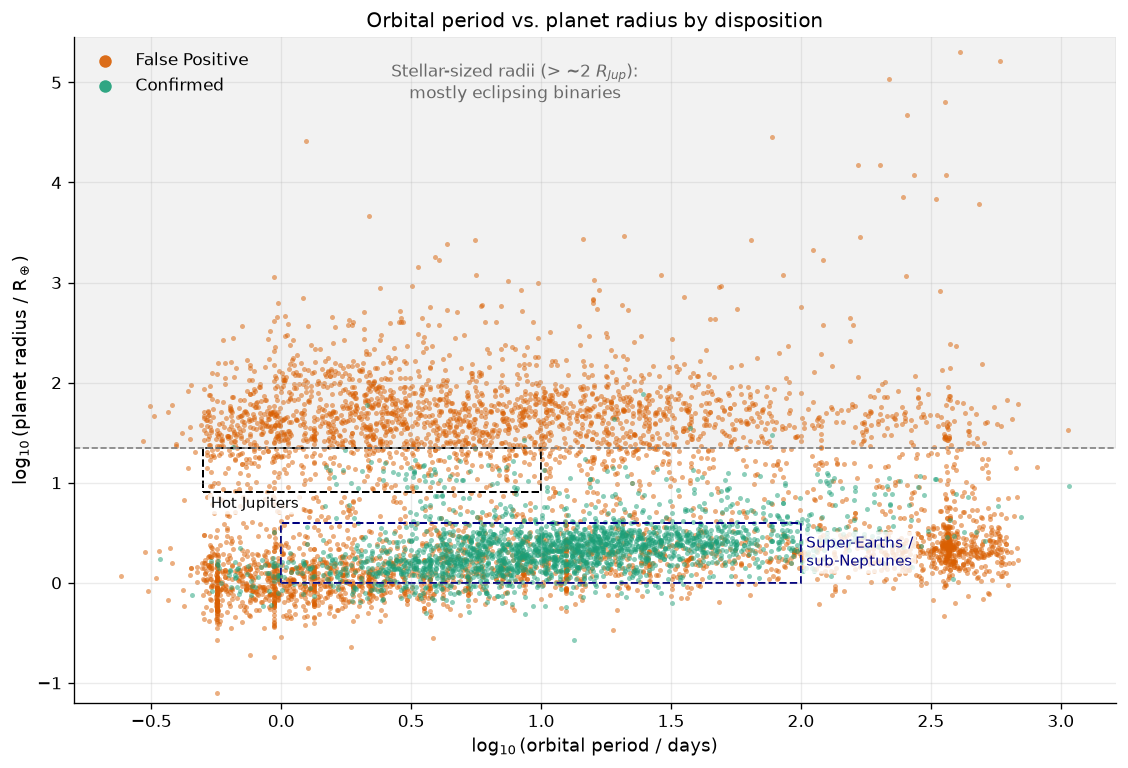

In [10]:
x, y_ = "log10_koi_period", "log10_koi_prad"
fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.scatter(fps[x], fps[y_], s=9, alpha=0.5, color=C_FP, label="False Positive", linewidths=0)
ax.scatter(planets[x], planets[y_], s=9, alpha=0.5, color=C_PLANET, label="Confirmed", linewidths=0)

R_STELLAR = np.log10(22.0)
y_top = data[y_].max() + 0.15
ax.axhspan(R_STELLAR, y_top, color="gray", alpha=0.10, zorder=0)
ax.axhline(R_STELLAR, color="gray", ls="--", lw=1)
ax.text(0.9, y_top - 0.25, "Stellar-sized radii (> ~2 $R_{Jup}$):\nmostly eclipsing binaries",
        ha="center", va="top", fontsize=10, color="dimgray")

ax.add_patch(Rectangle((np.log10(0.5), np.log10(8)), 1 - np.log10(0.5), R_STELLAR - np.log10(8),
                       fill=False, ec="black", ls="--", lw=1.2))
ax.text(np.log10(0.5) + 0.03, np.log10(8) - 0.04, "Hot Jupiters", fontsize=9, va="top",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))

ax.add_patch(Rectangle((0, 0), 2, np.log10(4), fill=False, ec="navy", ls="--", lw=1.2))
ax.text(2.02, np.log10(4) / 2, "Super-Earths /\nsub-Neptunes", fontsize=9, va="center", color="navy",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))

ax.set_xlabel(r"$\log_{10}$(orbital period / days)")
ax.set_ylabel(r"$\log_{10}$(planet radius / R$_\oplus$)")
ax.set_ylim(data[y_].min() - 0.1, y_top)
ax.set_title("Orbital period vs. planet radius by disposition")
leg = ax.legend(loc="upper left", markerscale=2.5)
for h in leg.legend_handles:
    h.set_alpha(0.9)
plt.tight_layout()
plt.show()

### Plot 4: Correlation heatmap (multicollinearity check)

Strong correlations among predictors inflate the standard errors of logistic-regression coefficients. Besides the correlation matrix we compute **variance inflation factors**, $\text{VIF}_j = [R^{-1}]_{jj}$ where $R$ is the predictor correlation matrix (VIF > 10 is the usual warning level).

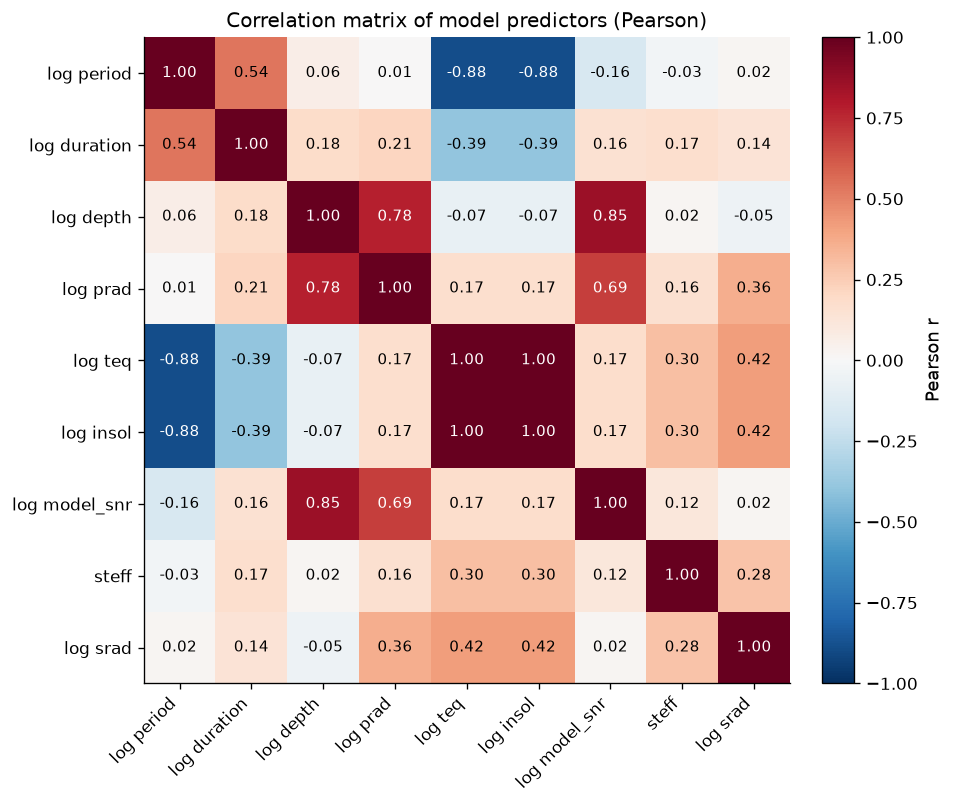

,VIF
log10_koi_period,570.2
log10_koi_duration,1.7
log10_koi_depth,7.9
log10_koi_prad,4.4
log10_koi_teq,341049.3
log10_koi_insol,340593.2
log10_koi_model_snr,5.1
koi_steff,20.2
log10_koi_srad,113.2


In [11]:
corr = data[FEATURES].corr()
labels = [f.replace("koi_", "").replace("log10_", "log ") for f in FEATURES]

fig, ax = plt.subplots(figsize=(8.2, 6.8))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels=labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels=labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 else "black")
ax.grid(False)
ax.set_title("Correlation matrix of model predictors (Pearson)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson r")
plt.tight_layout()
plt.show()

vif = pd.Series(np.diag(np.linalg.inv(corr.values)), index=FEATURES, name="VIF")
display(vif.round(1).to_frame())

**Multicollinearity warning.** `log10_koi_teq` and `log10_koi_insol` are almost perfectly correlated. This is expected physically: equilibrium temperature $T_{eq}\propto T_\star\sqrt{R_\star/a}$ and stellar flux at the planet $S\propto T_\star^4 R_\star^2/a^2$, so $\log S$ is nearly a linear function of $\log T_{eq}$. Because both are in the required predictor set we keep them, but we should expect **enormous VIFs and numerically unstable coefficients for these two variables** in Section 5 (typically large values of opposite sign that nearly cancel each other). This does not invalidate the other coefficients or the predictive performance, but the `teq` and `insol` estimates themselves cannot be interpreted. A common remedy would be to drop one of the pair.

## 5. Inferential Logistic Regression (`statsmodels`)

We model the log-odds of being a confirmed planet:

$$\log\frac{P(Y=1\mid \mathbf{x})}{1-P(Y=1\mid \mathbf{x})} = \beta_0 + \sum_{j=1}^{9}\beta_j z_j, \qquad z_j=\frac{x_j-\bar{x}_j^{\text{train}}}{s_j^{\text{train}}}$$

**Procedure:** 80/20 stratified split (`random_state=42`); `StandardScaler` is **fit on the training set only** and then applied to the test set (no information from the test set leaks into preprocessing). Because predictors are standardised, each $\beta_j$ is the change in log-odds per **one standard deviation** of predictor $j$ (holding the others fixed), and $e^{\beta_j}$ is the corresponding odds ratio.

In [12]:
X = data[FEATURES]
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

scaler = StandardScaler().fit(X_train)           # fit on TRAIN only
X_train_sc = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_sc = pd.DataFrame(scaler.transform(X_test), columns=FEATURES, index=X_test.index)

print(f"Train: {len(X_train):,} rows  | confirmed share = {y_train.mean():.3f}")
print(f"Test : {len(X_test):,} rows  | confirmed share = {y_test.mean():.3f}")

logit_res = sm.Logit(y_train, sm.add_constant(X_train_sc)).fit(disp=0, maxiter=200)
print(logit_res.summary())

Train: 5,612 rows  | confirmed share = 0.327
Test : 1,403 rows  | confirmed share = 0.326
                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                 5612
Model:                          Logit   Df Residuals:                     5602
Method:                           MLE   Df Model:                            9
Date:                Tue, 17 Nov 2026   Pseudo R-squ.:                  0.2906
Time:                        00:33:34   Log-Likelihood:                -2515.6
converged:                       True   LL-Null:                       -3546.2
Covariance Type:            nonrobust   LLR p-value:                     0.000
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -1.8135      0.091    -19.885      0.000      -1.992      -1.635
log10_koi_peri

In [13]:
ci = logit_res.conf_int()
ci.columns = ["lo", "hi"]

coef_tbl = pd.DataFrame({
    "Std. coefficient (beta)": logit_res.params,
    "Odds ratio exp(beta)": np.exp(logit_res.params),
    "OR 95% CI lower": np.exp(ci["lo"]),
    "OR 95% CI upper": np.exp(ci["hi"]),
    "p-value": logit_res.pvalues,
}).drop(index="const").sort_values("p-value")

coef_show = coef_tbl.copy()
for c in coef_show.columns[:4]:
    coef_show[c] = coef_show[c].map("{:.3g}".format)
coef_show["p-value"] = coef_show["p-value"].map("{:.2e}".format)
coef_show["significant (p<0.05)"] = np.where(coef_tbl["p-value"] < 0.05, "yes", "no")
display(coef_show)
print(f"McFadden pseudo-R^2 = {logit_res.prsquared:.3f}")

,Std. coefficient (beta),Odds ratio exp(beta),OR 95% CI lower,OR 95% CI upper,p-value,significant (p<0.05)
log10_koi_model_snr,2.43,11.4,9.23,14.1,1.88e-113,yes
log10_koi_duration,-0.733,0.48,0.433,0.533,4.01e-44,yes
log10_koi_prad,-5.09,0.00614,0.00255,0.0148,8.22e-30,yes
log10_koi_srad,3.06,21.3,8.29,54.6,2.06e-10,yes
log10_koi_depth,1.03,2.79,1.39,5.59,3.86e-03,yes
log10_koi_period,-2.74,0.0645,0.00873,0.476,7.20e-03,yes
log10_koi_insol,-43.6,1.19e-19,1.14e-34,0.000124,1.35e-02,yes
log10_koi_teq,39.2,1.03e+17,100,1.06e+32,2.63e-02,yes
koi_steff,0.178,1.2,0.81,1.76,3.69e-01,no


McFadden pseudo-R^2 = 0.291


### Interpretation of the three most significant predictors

Odds ratios below are per **+1 SD** of the (log-transformed) predictor, all else held constant. Predictors are ranked by p-value in the table above.

1. **`log10_koi_model_snr` (OR ≈ 11):** a stronger, cleaner transit signal sharply raises the odds of confirmation. Low-SNR signals are statistically fragile and are the ones most often produced by noise or instrumental artefacts, while confirmed planets tend to be detected at high significance.
2. **`log10_koi_duration` (OR ≈ 0.48):** at a fixed period and radius, a longer transit makes a planet *less* likely. For a given star, duration is geometrically tied to the orbital period, so a duration that is long for the period points to a different geometry than a planet on a small orbit (for example a blended or stellar eclipse).
3. **`log10_koi_prad` (OR ≈ 0.006):** larger inferred radii strongly lower the odds of being a planet. This matches Plot 3: objects with very large "radii" are usually stellar companions. Note this is conditional on depth and stellar radius, which are partly collinear with it ($R_p\approx R_\star\sqrt{\text{depth}}$), so the individual `koi_prad`, `koi_depth` and `koi_srad` coefficients should be read jointly (the opposite signs of `koi_depth` and `koi_prad` partly reflect this).

`koi_srad` (OR ≈ 21) is also significant, and `koi_depth` and `koi_period` are significant at the 0.01 level but with very wide confidence intervals.

**Do not interpret `log10_koi_teq` and `log10_koi_insol`.** Their standardised coefficients are very large and of opposite sign (roughly +39 and −44), with odds ratios of astronomical size and confidence intervals spanning many orders of magnitude. Their nominal p-values (< 0.05) are an artefact of near-perfect collinearity (VIF ≈ 3×10⁵, Plot 4): the model can only identify a tiny *difference* between the two, not either effect individually. The same collinearity inflates the standard errors of `koi_period` and `koi_srad`. Note also that all effects are *associations* in a catalogue shaped by Kepler's vetting process, not causal effects.

## 6. Predictive Evaluation & Threshold Diagnostics (`scikit-learn`)

We now fit `sklearn.linear_model.LogisticRegression` on the same scaled training data and evaluate on the **held-out test set**. (scikit-learn applies mild L2 regularisation by default, which also stabilises the collinear `teq`/`insol` pair, so its coefficients differ slightly from the unpenalised `statsmodels` fit; the goal here is prediction.) The default classification threshold is 0.5.

In [14]:
clf = LogisticRegression(max_iter=1000, random_state=SEED)
clf.fit(X_train_sc, y_train)

y_prob = clf.predict_proba(X_test_sc)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
}, name="Test-set value")
print("Test-set performance at threshold = 0.50 (positive class = CONFIRMED)")
for k, v in metrics.items():
    print(f"  {k:<10s} {v:.4f}")
print(f"\nBaseline accuracy of always predicting FALSE POSITIVE: {1 - y_test.mean():.4f}")

Test-set performance at threshold = 0.50 (positive class = CONFIRMED)
  Accuracy   0.7548
  Precision  0.6532
  Recall     0.5306
  F1-Score   0.5855
  ROC-AUC    0.8334

Baseline accuracy of always predicting FALSE POSITIVE: 0.6736


### Plot 5: Confusion matrix and ROC curve

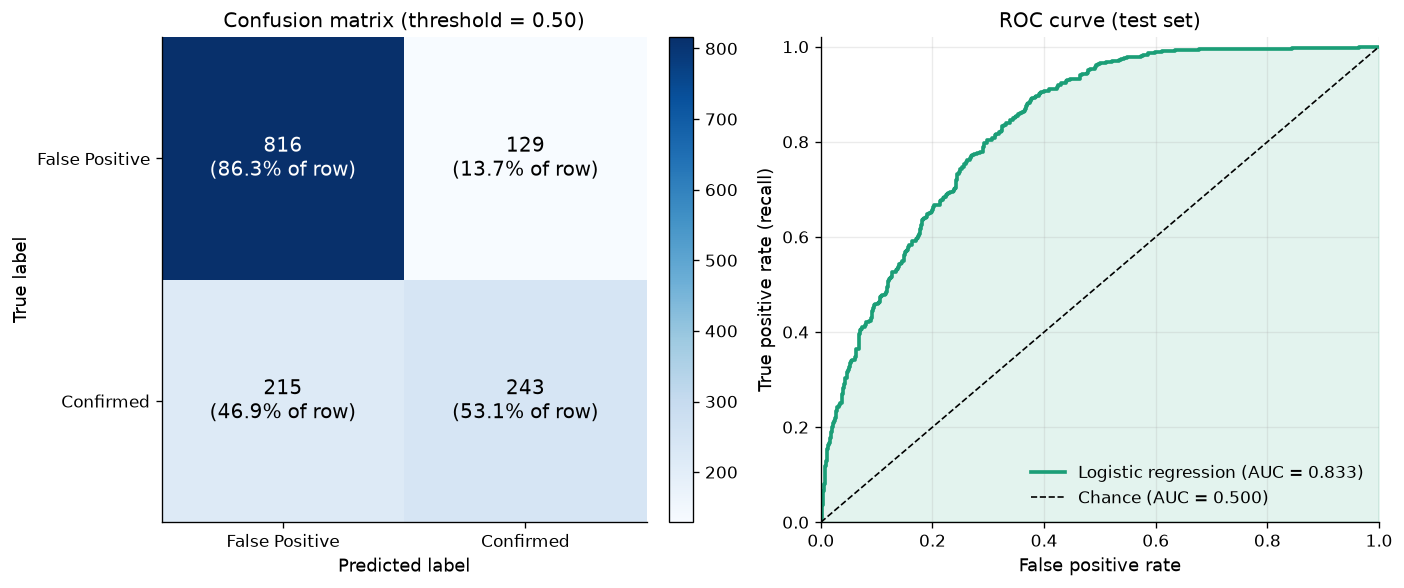

In [15]:
cm = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
class_names = ["False Positive", "Confirmed"]

fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))

# Left: confusion matrix
im = ax_cm.imshow(cm, cmap="Blues")
ax_cm.set_xticks([0, 1], labels=class_names)
ax_cm.set_yticks([0, 1], labels=class_names)
ax_cm.set_xlabel("Predicted label")
ax_cm.set_ylabel("True label")
ax_cm.set_title("Confusion matrix (threshold = 0.50)")
for i in range(2):
    for j in range(2):
        share = 100 * cm[i, j] / cm[i].sum()
        ax_cm.text(j, i, f"{cm[i, j]:,}\n({share:.1f}% of row)", ha="center", va="center",
                   fontsize=12, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax_cm.grid(False)
fig.colorbar(im, ax=ax_cm, fraction=0.046, pad=0.04)

# Right: ROC curve
ax_roc.plot(fpr, tpr, color=C_PLANET, lw=2.2, label=f"Logistic regression (AUC = {auc:.3f})")
ax_roc.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (AUC = 0.500)")
ax_roc.fill_between(fpr, tpr, alpha=0.12, color=C_PLANET)
ax_roc.set_xlabel("False positive rate")
ax_roc.set_ylabel("True positive rate (recall)")
ax_roc.set_title("ROC curve (test set)")
ax_roc.set_xlim(0, 1)
ax_roc.set_ylim(0, 1.02)
ax_roc.legend(loc="lower right")

plt.tight_layout()
plt.show()

### Plot 6: Precision, recall and F1 vs. classification threshold

The default 0.5 threshold is arbitrary. Sweeping it from 0.1 to 0.9 shows the trade-off between *finding more planets* (recall) and *being right when we say "planet"* (precision).

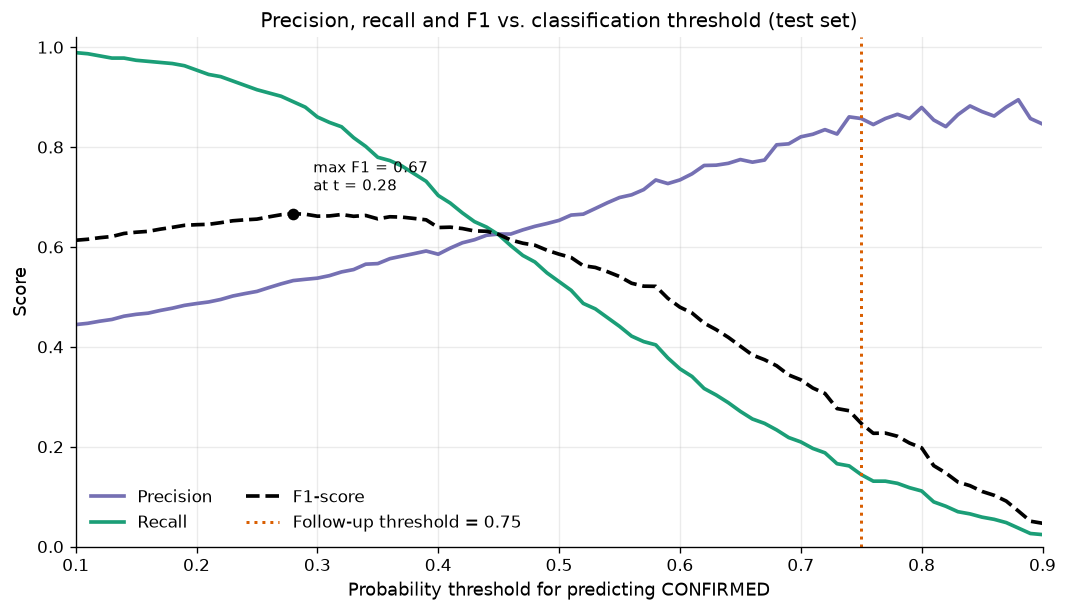

,flagged as planet,true planets among them,false positives among them,planets missed,precision,recall
threshold,,,,,,
0.25,820,419,401,39,0.511,0.915
0.50,372,243,129,215,0.653,0.531
0.75,77,66,11,392,0.857,0.144
0.90,13,11,2,447,0.846,0.024


In [16]:
thresholds = np.round(np.arange(0.10, 0.9001, 0.01), 2)
prec, rec, f1s = [], [], []
for t in thresholds:
    pred_t = (y_prob >= t).astype(int)
    prec.append(precision_score(y_test, pred_t, zero_division=0))
    rec.append(recall_score(y_test, pred_t, zero_division=0))
    f1s.append(f1_score(y_test, pred_t, zero_division=0))
prec, rec, f1s = map(np.array, (prec, rec, f1s))

best_idx = int(np.argmax(f1s))
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(thresholds, prec, color="#7570b3", lw=2.2, label="Precision")
ax.plot(thresholds, rec, color=C_PLANET, lw=2.2, label="Recall")
ax.plot(thresholds, f1s, color="black", lw=2.2, ls="--", label="F1-score")
ax.axvline(0.75, color=C_FP, ls=":", lw=1.8, label="Follow-up threshold = 0.75")
ax.scatter([thresholds[best_idx]], [f1s[best_idx]], color="black", zorder=5)
ax.annotate(f"max F1 = {f1s[best_idx]:.2f}\nat t = {thresholds[best_idx]:.2f}",
            (thresholds[best_idx], f1s[best_idx]), textcoords="offset points",
            xytext=(12, 14), fontsize=9)
ax.set_xlabel("Probability threshold for predicting CONFIRMED")
ax.set_ylabel("Score")
ax.set_xlim(0.1, 0.9)
ax.set_ylim(0, 1.02)
ax.set_title("Precision, recall and F1 vs. classification threshold (test set)")
ax.legend(loc="lower left", ncol=2)
plt.tight_layout()
plt.show()

summary_t = pd.DataFrame({"threshold": [0.25, 0.50, 0.75, 0.90]})
rows = []
for t in summary_t["threshold"]:
    p = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({"threshold": t, "flagged as planet": tp + fp, "true planets among them": tp,
                 "false positives among them": fp, "planets missed": fn,
                 "precision": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn)})
display(pd.DataFrame(rows).set_index("threshold").round(3))

**Why raise the threshold to ≈ 0.75 when allocating follow-up telescope time?**

Follow-up confirmation (radial-velocity spectroscopy, high-resolution imaging, space-based photometry) costs many hours of oversubscribed telescope time per target. The two error types have very different costs:

* A **false positive prediction** (a non-planet we call "planet") wastes scarce telescope time.
* A **missed planet** (a real planet scored below the threshold) is not lost forever: it stays in the catalogue and can be re-scored or picked up later.

Raising the probability threshold makes the classifier more conservative, so that only objects with high estimated probability of being planets are sent for follow-up. As the table shows, **precision rises while recall falls**: the observing programme is dominated by real planets, at the cost of leaving more real planets unobserved for now. The right threshold depends on the observing budget and the relative cost of the two errors; F1 weights them equally, whereas a telescope-time-limited programme typically values precision more.

## 7. Conclusion & Limitations

**Findings**

* After removing `CANDIDATE` rows and incomplete records, we analysed a sample of about 7,000 KOIs (≈ one-third confirmed). Log-transforming the right-skewed predictors greatly reduced skewness.
* Univariate Welch and Mann-Whitney tests show that confirmed planets and false positives differ systematically in most physical properties (largest effect for planet radius, Cohen's d ≈ -0.8; for SNR only the means differ, not the medians).
* In the multivariable `statsmodels` logit, transit **SNR** (strongly positive), **duration** and **planet radius** (both negative) are the most significant predictors. This agrees with the astrophysics: weak signals and stellar-sized "planets" are the typical false positives.
* Predictive performance on the test set is moderate (ROC-AUC ≈ 0.83). The model ranks signals well but at a 0.5 threshold misses a large share of confirmed planets, and the threshold can be tuned to the cost of follow-up observations.

**Limitations**

1. **Linear decision boundary in log-odds space.** Logistic regression assumes each predictor acts additively and linearly on the log-odds. Interactions (for example, period × duration, which jointly encode orbital geometry) and non-monotonic effects (a radius that is "too small" *and* "too large" can both be suspicious) are not captured. Tree ensembles or models with interaction terms would likely perform better.
2. **Multicollinearity.** `koi_teq` and `koi_insol` are nearly redundant (and `koi_period`, `koi_srad`, `koi_steff` are involved in the same relations), which makes their individual coefficients meaningless (huge, opposite-signed values) even though predictions are stable. Dropping one of the pair is the natural fix.
3. **Label noise and selection effects.** "Confirmed" and "False Positive" labels come from a heterogeneous vetting process, and confirmation depends on follow-up resources, which favours bright stars and large, easy-to-observe planets. `CANDIDATE` rows were excluded, so the model is evaluated only on already-resolved cases.
4. **Class imbalance and a single split.** We used one stratified 80/20 split; cross-validation would give uncertainty estimates for the performance metrics.
5. **Association, not causation.** Odds ratios describe patterns in this catalogue and should not be read as physical causal effects.